# Studi Kasus 4 — *Introduction to Machine Learning*

**Pemateri:** Dr. Taniza Tajuddin (Senior Lecturer, Fakulti Sains Komputer dan Matematik, Universiti Teknologi MARA
Cawangan Kedah, Malaysia)
**Video (2 bagian):**
* Bagian 1 — https://www.youtube.com/live/FTf9eiE1Tw0
* Bagian 2 — https://www.youtube.com/live/0LFeuSypYro

**Seri:** Informatics Practitioner Lecture Series 2026 — Prodi Informatika Universitas Bengkulu

---

## Ringkasan materi pemateri

1. **Dari *rule-based* ke *data-driven***: pemrograman tradisional menulis aturan *if-then* secara manual;
   *machine learning* (ML) membiarkan algoritma **menemukan pola & aturan dari data**.
2. **Posisi ML**: AI ⊃ ML ⊃ *Deep Learning*. Sejarah singkat: gagasan mesin cerdas (1950-an) → sistem pakar
   (1970–80-an) → pohon keputusan, SVM, jaringan saraf (1990-an) → *big data* (2000–2010) → *deep learning*, NLP, LLM.
3. **Alur kerja ML**: kumpulkan data → *preprocessing* (tangani *missing value*, duplikat, ubah teks ke angka,
   normalisasi) → bagi data latih/uji (80/20 atau 70/30) → pilih model → latih → evaluasi → *deploy* & pantau.
   *Data berkualitas → prediksi akurat.*
4. **Jenis ML**:
   * **Supervised** (data berlabel): **klasifikasi** (spam/bukan, pinjaman disetujui/ditolak, penyakit) dan
     **regresi** (harga rumah, suhu, penjualan).
   * **Unsupervised** (tanpa label): **clustering** (K-Means, hierarkis, DBSCAN, GMM — segmentasi pelanggan),
     **reduksi dimensi** (PCA, t-SNE, autoencoder), **deteksi anomali** (Isolation Forest — penipuan kartu kredit),
     **association rule** (*support, confidence, lift* — "beli roti, beli telur").
   * **Reinforcement learning** (agen–lingkungan–aksi–*reward/penalty*, mis. mobil otonom, Q-learning).
   * **Semi-supervised** (sedikit data berlabel + banyak tak berlabel, mis. *self-training*).
5. **Evaluasi**: klasifikasi → *accuracy, precision, recall, F1, confusion matrix*; regresi → MAE, R²;
   waspadai ***overfitting*** (akurasi terlalu sempurna) dan ***underfitting***.
6. **Tantangan & etika**: kualitas data, bias (persetujuan pinjaman, rekrutmen), transparansi/*explainability*,
   privasi, akuntabilitas, biaya komputasi.

## Latar belakang studi kasus

**"Bank Daerah Bengkulu Digital"** (fiktif) ingin memakai ML untuk enam kebutuhan yang mewakili seluruh jenis ML pada
materi:

| Bagian | Kebutuhan bank / mitra | Jenis ML | Contoh pemateri |
|---|---|---|---|
| A | Menyaring SMS penipuan nasabah | *Rule-based* vs *supervised* | spam vs not spam |
| B | Menaksir harga rumah agunan KPR | Regresi | *house price prediction* |
| C | Rekomendasi persetujuan pinjaman | Klasifikasi | *loan approval* |
| D | Segmentasi nasabah untuk pemasaran | Clustering + PCA | *customer segmentation* |
| E | Deteksi transaksi kartu mencurigakan | Deteksi anomali | transaksi luar negeri |
| F | Penempatan produk di minimarket mitra | Association rule | roti → telur |
| G | Memanfaatkan pesan yang belum berlabel | Semi-supervised | 1.000 berlabel vs 30.000 tak berlabel |
| H | Robot kurir gudang menghindari tabrakan | Reinforcement learning | *self-driving car* |

Semua data **sintetis** (dibangkitkan dengan *seed* tetap) agar dapat dijalankan ulang di Google Colab.

## 0. Persiapan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, IsolationForest
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, ConfusionMatrixDisplay, silhouette_score)

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(7)

## A. Pemrograman tradisional vs *machine learning*: filter SMS penipuan

**Pendekatan tradisional**: programmer menulis aturan (*if pesan mengandung "menang" atau "hadiah" → penipuan*).
**Pendekatan ML**: algoritma mempelajari kata-kata penanda dari contoh pesan berlabel.

In [2]:
penipuan_tpl = [
    "selamat anda {menang} {hadiah} senilai rp{n} juta klik {link}",
    "nasabah yth akun anda {blokir} segera verifikasi di {link}",
    "pinjaman cepat cair {n} juta tanpa agunan hubungi {wa}",
    "anda terpilih mendapat {hadiah} dari bank silakan transfer biaya admin rp{n}00 ribu",
    "kode otp anda dibutuhkan petugas kami untuk {verif} rekening, balas segera",
    "promo {hadiah} khusus hari ini, isi data kartu atm di {link}",
    "paket anda tertahan di gudang, lengkapi alamat di {link}",
    "mama ganti nomor, tolong transfer dulu rp{n}00 ribu ke rekening ini",
]
normal_tpl = [
    "besok kuliah jam {jam} di gedung {g} jangan lupa bawa laptop",
    "transfer uang kos sudah masuk ya rp{n}00 ribu",
    "pengingat: tagihan kartu kredit anda jatuh tempo tanggal {tgl}",
    "rapat himpunan dipindah ke jam {jam} di ruang {g}",
    "paket anda sedang dikirim kurir estimasi tiba tanggal {tgl}",
    "mama sudah sampai rumah, nanti sore jemput adik ya",
    "terima kasih telah bertransaksi di atm kami pada tanggal {tgl}",
    "selamat ulang tahun nak, semoga suka {hadiah} dari mama",
    "klik link zoom kuliah pengganti jam {jam}: zoom.us/j/{n}",
    "selamat kamu {menang} lomba poster kemarin, ambil sertifikat di ruang {g}",
]
isian = dict(menang=["menang", "beruntung", "jadi pemenang"], hadiah=["hadiah", "mobil", "voucher", "saldo bonus"],
             blokir=["diblokir", "dibekukan", "ditangguhkan"], verif=["verifikasi", "aktivasi", "validasi"],
             link=["bit.ly/xyz", "s.id/promo", "bank-hadiah.com"], wa=["wa 0812xxxx", "0857xxxx"],
             jam=list("789") + ["10", "13"], g=list("ABCDEF"), tgl=[str(i) for i in range(1, 29)],
             n=[str(i) for i in range(1, 99)])

def isi(t):
    return t.format(**{k: rng.choice(v) for k, v in isian.items() if "{" + k + "}" in t})

sms = pd.DataFrame([(isi(rng.choice(penipuan_tpl)), 1) for _ in range(400)] +
                   [(isi(rng.choice(normal_tpl)), 0) for _ in range(600)], columns=["teks", "penipuan"])
sms.loc[rng.choice(len(sms), 20, replace=False), "penipuan"] ^= 1      # 2% label salah (kesalahan petugas)
sms_latih, sms_uji = train_test_split(sms, test_size=0.3, stratify=sms.penipuan, random_state=0)

# Pendekatan 1: aturan buatan programmer
def aturan_manual(teks):
    return int(any(k in teks for k in ["menang", "hadiah", "klik"]))
pred_aturan = sms_uji.teks.apply(aturan_manual)

# Pendekatan 2: ML (TF-IDF + Naive Bayes)
model_sms = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB()).fit(sms_latih.teks, sms_latih.penipuan)
pred_ml = model_sms.predict(sms_uji.teks)

for nama, pred in [("Aturan manual", pred_aturan), ("Machine learning", pred_ml)]:
    print(f"{nama:16s} → akurasi {accuracy_score(sms_uji.penipuan, pred):.3f}, "
          f"presisi {precision_score(sms_uji.penipuan, pred):.3f}, recall {recall_score(sms_uji.penipuan, pred):.3f}")

baru = ["akun anda dibekukan, verifikasi data di s.id/promo", "nanti jam 10 kumpul di gedung C ya"]
print("\nPesan baru:", dict(zip(baru, model_sms.predict(baru))))

Aturan manual    → akurasi 0.603, presisi 0.520, recall 0.320
Machine learning → akurasi 0.987, presisi 0.992, recall 0.975

Pesan baru: {'akun anda dibekukan, verifikasi data di s.id/promo': np.int64(1), 'nanti jam 10 kumpul di gedung C ya': np.int64(0)}


Aturan manual melewatkan pola penipuan yang tidak terpikirkan programmer (mis. "akun dibekukan", "kode OTP",
"mama ganti nomor") dan salah menandai pesan wajar yang kebetulan memuat kata "hadiah"/"klik"/"menang". Model ML
menemukan kata penanda itu sendiri dari data. Namun ML tetap bergantung pada **kualitas &
keragaman data latih**.

## B. Regresi — taksiran harga rumah agunan KPR di Kota Bengkulu

Fitur (seperti contoh pemateri): luas bangunan, luas tanah, jumlah kamar, lokasi (kecamatan), jarak ke pusat kota,
umur bangunan. Target: harga (juta rupiah).

In [3]:
n = 800
kec = rng.choice(["Gading Cempaka", "Ratu Samban", "Muara Bangkahulu", "Selebar", "Singaran Pati", "Kampung Melayu"], n)
premi_kec = pd.Series({"Gading Cempaka": 1.25, "Ratu Samban": 1.30, "Muara Bangkahulu": 1.05, "Selebar": 0.90,
                       "Singaran Pati": 1.10, "Kampung Melayu": 0.85})
rumah = pd.DataFrame({
    "luas_bangunan": rng.normal(90, 30, n).clip(30, 250).round(),
    "luas_tanah": rng.normal(150, 50, n).clip(60, 400).round(),
    "kamar_tidur": rng.integers(1, 6, n),
    "kamar_mandi": rng.integers(1, 4, n),
    "kecamatan": kec,
    "jarak_pusat_km": rng.gamma(2.5, 2, n).round(1),
    "umur_bangunan": rng.integers(0, 30, n),
})
rumah["harga_juta"] = ((2.6 * rumah.luas_bangunan + 1.1 * rumah.luas_tanah + 25 * rumah.kamar_tidur
                        + 18 * rumah.kamar_mandi - 6 * rumah.jarak_pusat_km - 3 * rumah.umur_bangunan + 80)
                       * premi_kec[kec].values * rng.normal(1, 0.08, n)).round()
# kotoran data: missing value & outlier input salah
rumah.loc[rng.choice(n, 30, replace=False), "luas_tanah"] = np.nan
rumah.loc[rng.choice(n, 4, replace=False), "harga_juta"] = 99999
rumah.describe().round(1)

,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,jarak_pusat_km,umur_bangunan,harga_juta
count,800.0,770.0,800.0,800.0,800.0,800.0,800.0
mean,90.0,152.4,3.0,2.0,5.0,14.4,1053.8
std,29.2,49.1,1.4,0.8,3.1,8.4,7019.9
min,30.0,60.0,1.0,1.0,0.1,0.0,213.0
25%,69.0,116.0,2.0,1.0,2.7,7.0,452.8
50%,88.0,153.0,3.0,2.0,4.4,15.0,549.0
75%,110.0,186.0,4.0,3.0,6.7,21.0,647.0
max,175.0,310.0,5.0,3.0,19.9,29.0,99999.0


In [4]:
# Preprocessing: buang outlier (harga di luar batas wajar IQR), imputasi median, one-hot, standardisasi
q1, q3 = rumah.harga_juta.quantile([0.25, 0.75])
rumah_bersih = rumah[rumah.harga_juta <= q3 + 3 * (q3 - q1)]
print("Outlier dibuang:", len(rumah) - len(rumah_bersih))

NUM = ["luas_bangunan", "luas_tanah", "kamar_tidur", "kamar_mandi", "jarak_pusat_km", "umur_bangunan"]
pre_rumah = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
    ("kat", OneHotEncoder(handle_unknown="ignore"), ["kecamatan"])])
Xr, yr = rumah_bersih[NUM + ["kecamatan"]], rumah_bersih.harga_juta
Xr_l, Xr_u, yr_l, yr_u = train_test_split(Xr, yr, test_size=0.2, random_state=0)   # 80% latih, 20% uji

model_reg = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (derajat 2)": Pipeline([("poly", PolynomialFeatures(2)), ("lr", LinearRegression())]),
    "Support Vector Regression": SVR(C=300, epsilon=5),
    "Random Forest Regressor": RandomForestRegressor(300, random_state=0),
}
hasil_reg = []
for nama, m in model_reg.items():
    pipe = Pipeline([("pre", pre_rumah), ("m", m)]).fit(Xr_l, yr_l)
    p = pipe.predict(Xr_u)
    hasil_reg.append({"model": nama, "MAE (juta)": mean_absolute_error(yr_u, p),
                      "RMSE (juta)": mean_squared_error(yr_u, p) ** 0.5, "R²": r2_score(yr_u, p)})
    model_reg[nama] = pipe
pd.DataFrame(hasil_reg).set_index("model").round(3)

Outlier dibuang: 4


,MAE (juta),RMSE (juta),R²
model,,,
Linear Regression,39.182,47.889,0.909
Polynomial Regression (derajat 2),37.164,47.621,0.910
Support Vector Regression,42.204,56.266,0.875
Random Forest Regressor,54.847,67.573,0.819


In [5]:
rumah_baru = pd.DataFrame([{"luas_bangunan": 120, "luas_tanah": 180, "kamar_tidur": 3, "kamar_mandi": 2,
                            "kecamatan": "Gading Cempaka", "jarak_pusat_km": 3.5, "umur_bangunan": 5}])
for nama in ["Linear Regression", "Random Forest Regressor"]:
    print(f"{nama:25s}: taksiran harga ≈ Rp{model_reg[nama].predict(rumah_baru)[0]:,.0f} juta")

Linear Regression        : taksiran harga ≈ Rp798 juta
Random Forest Regressor  : taksiran harga ≈ Rp764 juta


### B.1 *Overfitting* vs *underfitting*
Pemateri mengingatkan: akurasi latih yang "terlalu sempurna" justru mencurigakan. Kita ubah kompleksitas model
(derajat polinomial) dan bandingkan galat latih vs galat uji.

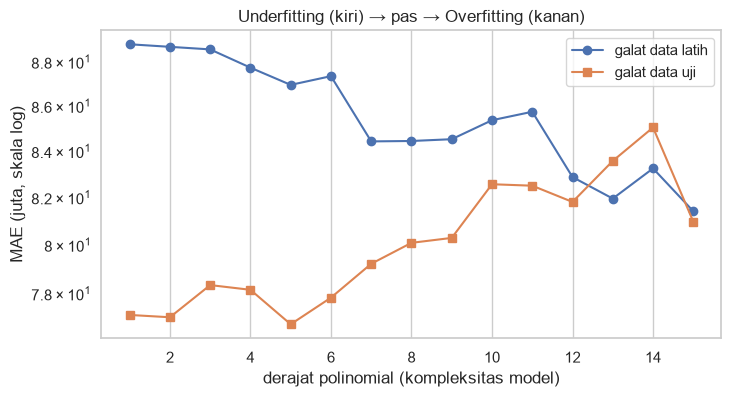

In [6]:
x1 = rumah_bersih[["luas_bangunan"]].values[:120]; y1 = rumah_bersih.harga_juta.values[:120]
x1_l, x1_u, y1_l, y1_u = train_test_split(x1, y1, test_size=0.4, random_state=1)
deg, err_l, err_u = range(1, 16), [], []
for d in deg:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression()).fit(x1_l, y1_l)
    err_l.append(mean_absolute_error(y1_l, m.predict(x1_l))); err_u.append(mean_absolute_error(y1_u, m.predict(x1_u)))
plt.figure(figsize=(8, 4))
plt.plot(deg, err_l, "o-", label="galat data latih"); plt.plot(deg, err_u, "s-", label="galat data uji")
plt.yscale("log"); plt.xlabel("derajat polinomial (kompleksitas model)"); plt.ylabel("MAE (juta, skala log)")
plt.title("Underfitting (kiri) → pas → Overfitting (kanan)"); plt.legend(); plt.show()

## C. Klasifikasi — rekomendasi persetujuan pinjaman
Fitur sesuai contoh pemateri: riwayat kredit, rasio utang (*debt ratio*), status pekerjaan, pendapatan, nilai & tenor
pinjaman. Label: disetujui (1) / ditolak (0) dari keputusan analis kredit di masa lalu.

In [7]:
n = 1500
pinjaman = pd.DataFrame({
    "pendapatan_juta": rng.lognormal(1.6, 0.45, n).round(2),
    "rasio_utang": rng.beta(2, 5, n).round(2),
    "riwayat_kredit": rng.choice(["baik", "cukup", "buruk"], n, p=[0.6, 0.28, 0.12]),
    "status_kerja": rng.choice(["tetap", "kontrak", "wiraswasta"], n, p=[0.5, 0.3, 0.2]),
    "nilai_pinjaman_juta": rng.lognormal(3.2, 0.6, n).round(1),
    "tenor_bulan": rng.choice([12, 24, 36, 48, 60], n),
})
cicilan_rasio = (pinjaman.nilai_pinjaman_juta / pinjaman.tenor_bulan) / pinjaman.pendapatan_juta
skor = (2.2 - 4.0 * pinjaman.rasio_utang - 3.0 * cicilan_rasio
        + pinjaman.riwayat_kredit.map({"baik": 1.2, "cukup": 0.0, "buruk": -2.5})
        + pinjaman.status_kerja.map({"tetap": 0.6, "kontrak": -0.1, "wiraswasta": 0.0}) + rng.normal(0, 0.6, n))
pinjaman["disetujui"] = (skor > 0).astype(int)
print("Proporsi disetujui:", pinjaman.disetujui.mean().round(3))

Xp, yp = pinjaman.drop(columns="disetujui"), pinjaman.disetujui
pre_p = ColumnTransformer([("num", StandardScaler(), ["pendapatan_juta", "rasio_utang", "nilai_pinjaman_juta", "tenor_bulan"]),
                           ("kat", OneHotEncoder(), ["riwayat_kredit", "status_kerja"])])
Xp_l, Xp_u, yp_l, yp_u = train_test_split(Xp, yp, test_size=0.2, stratify=yp, random_state=0)
model_kls = {"Logistic Regression": LogisticRegression(max_iter=1000),
             "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=0),
             "K-Nearest Neighbors": KNeighborsClassifier(15),
             "Support Vector Machine": SVC(),
             "Random Forest": RandomForestClassifier(300, random_state=0)}
hasil_kls = []
for nama, m in model_kls.items():
    pipe = Pipeline([("pre", pre_p), ("m", m)])
    cv = cross_val_score(pipe, Xp_l, yp_l, cv=5, scoring="f1")
    pipe.fit(Xp_l, yp_l); p = pipe.predict(Xp_u)
    hasil_kls.append({"model": nama, "F1 CV-5 (rata±sd)": f"{cv.mean():.3f} ± {cv.std():.3f}",
                      "akurasi uji": accuracy_score(yp_u, p), "presisi": precision_score(yp_u, p),
                      "recall": recall_score(yp_u, p), "F1 uji": f1_score(yp_u, p)})
    model_kls[nama] = pipe
pd.DataFrame(hasil_kls).set_index("model").round(3)

Proporsi disetujui: 0.765


,F1 CV-5 (rata±sd),akurasi uji,presisi,recall,F1 uji
model,,,,,
Logistic Regression,0.949 ± 0.012,0.910,0.928,0.957,0.942
Decision Tree,0.921 ± 0.013,0.877,0.894,0.952,0.922
K-Nearest Neighbors,0.929 ± 0.012,0.883,0.876,0.987,0.928
Support Vector Machine,0.947 ± 0.007,0.933,0.938,0.978,0.957
Random Forest,0.942 ± 0.012,0.913,0.925,0.965,0.945


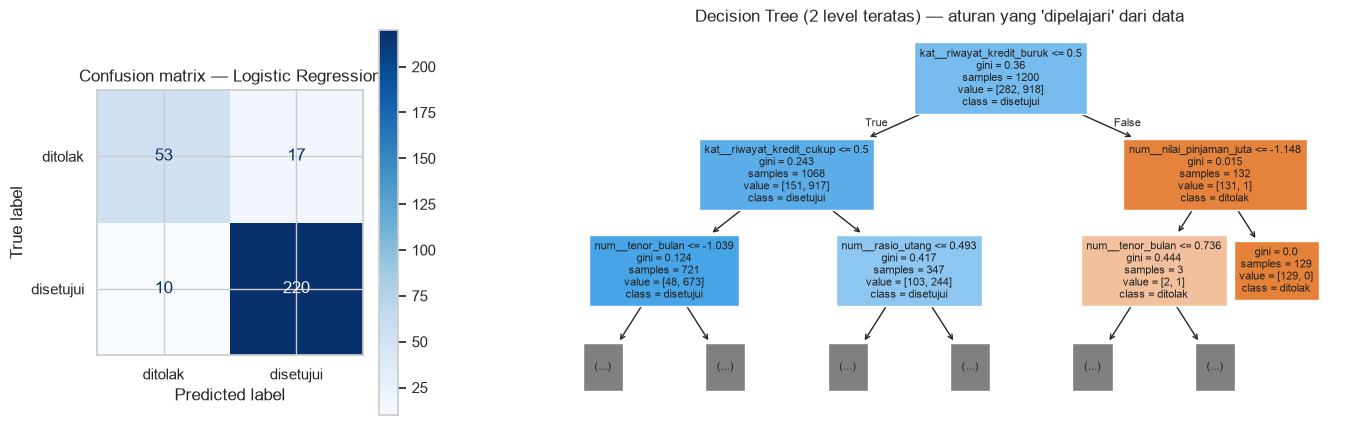

              precision    recall  f1-score   support

     ditolak       0.84      0.76      0.80        70
   disetujui       0.93      0.96      0.94       230

    accuracy                           0.91       300
   macro avg       0.88      0.86      0.87       300
weighted avg       0.91      0.91      0.91       300



In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2.4]})
ConfusionMatrixDisplay.from_estimator(model_kls["Logistic Regression"], Xp_u, yp_u,
                                      display_labels=["ditolak", "disetujui"], cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix — Logistic Regression")
pohon = model_kls["Decision Tree"]
plot_tree(pohon.named_steps["m"], feature_names=pohon.named_steps["pre"].get_feature_names_out(), max_depth=2,
          class_names=["ditolak", "disetujui"], filled=True, fontsize=8, ax=ax[1])
ax[1].set_title("Decision Tree (2 level teratas) — aturan yang 'dipelajari' dari data"); plt.show()
print(classification_report(yp_u, model_kls["Logistic Regression"].predict(Xp_u), target_names=["ditolak", "disetujui"]))

**Catatan etika (dari materi):** model pinjaman bisa mewarisi **bias** keputusan masa lalu. Fitur sensitif
(jenis kelamin, suku, agama) tidak boleh dipakai, keputusan harus dapat **dijelaskan**, dan tetap ada
**pengawasan manusia** untuk kasus yang ditolak.

## D. Clustering — segmentasi nasabah (K-Means) + reduksi dimensi (PCA)

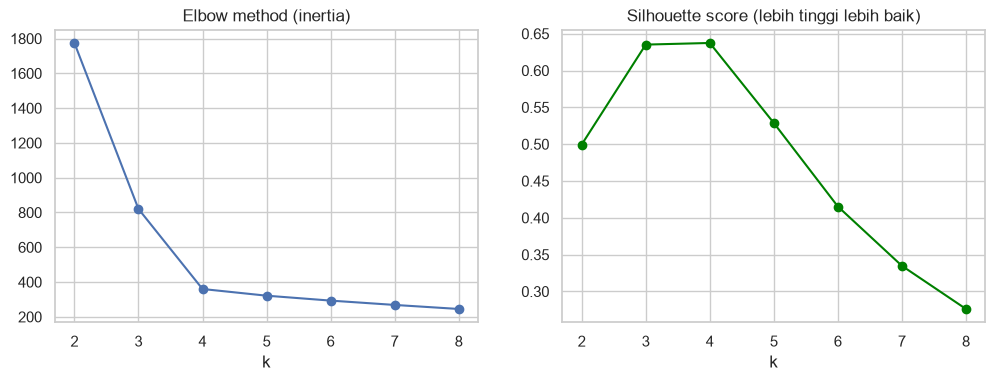

k terbaik menurut silhouette: 4


In [9]:
n = 900
segmen_asli = rng.choice(4, n, p=[0.35, 0.25, 0.15, 0.25])
pusat = np.array([[4, 150, 30, 2],      # frekuensi/bln, rata belanja (ribu), hari sejak transaksi terakhir, kategori
                  [12, 120, 5, 5],
                  [6, 900, 10, 3],
                  [1.5, 80, 90, 1]])
sebar = np.array([1.5, 40, 10, 0.8])
nasabah = pd.DataFrame(np.abs(pusat[segmen_asli] + rng.normal(0, 1, (n, 4)) * sebar * [1, 1, 1, 1]),
                       columns=["frekuensi_bulanan", "rata_belanja_ribu", "hari_sejak_terakhir", "jumlah_kategori"])
Xc = StandardScaler().fit_transform(nasabah)

K = range(2, 9); inertia, sil = [], []
for k in K:
    km = KMeans(k, n_init=10, random_state=0).fit(Xc)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xc, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(K, inertia, "o-"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(K, sil, "o-", color="green"); ax[1].set_title("Silhouette score (lebih tinggi lebih baik)"); ax[1].set_xlabel("k")
plt.show()
k_terbaik = list(K)[int(np.argmax(sil))]
print("k terbaik menurut silhouette:", k_terbaik)

,frekuensi_bulanan,rata_belanja_ribu,hari_sejak_terakhir,jumlah_kategori,jumlah,nama_segmen
cluster,,,,,,
0,11.8,120.2,9.4,5.0,246,Pelanggan Loyal
1,1.8,77.7,88.9,1.1,235,Pelanggan Pasif (berisiko pergi)
2,5.9,904.2,11.9,3.0,137,Pembeli Premium
3,3.9,150.2,30.7,1.9,282,Pelanggan Reguler


PCA: 2 komponen menjelaskan 89.8% variasi dari 4 fitur


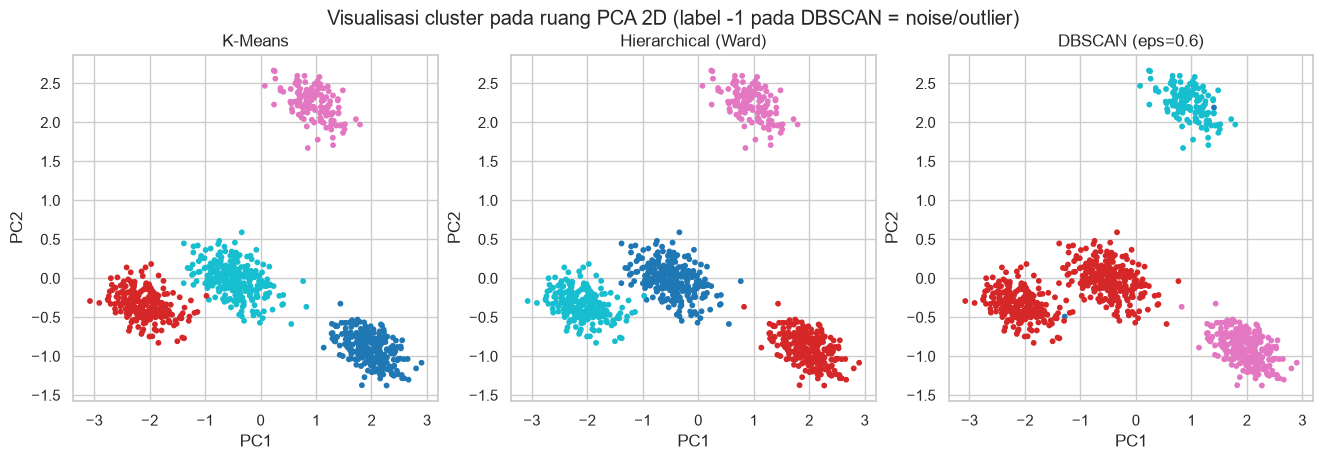

In [10]:
km = KMeans(k_terbaik, n_init=10, random_state=0).fit(Xc)
nasabah["cluster"] = km.labels_
profil = nasabah.groupby("cluster").mean().round(1)
profil["jumlah"] = nasabah.cluster.value_counts().sort_index()

def beri_nama(r):
    if r.rata_belanja_ribu > 500: return "Pembeli Premium"
    if r.frekuensi_bulanan > 9: return "Pelanggan Loyal"
    if r.hari_sejak_terakhir > 60: return "Pelanggan Pasif (berisiko pergi)"
    return "Pelanggan Reguler"
profil["nama_segmen"] = profil.apply(beri_nama, axis=1)
display(profil)

pca = PCA(2).fit(Xc); Z = pca.transform(Xc)
print(f"PCA: 2 komponen menjelaskan {100 * pca.explained_variance_ratio_.sum():.1f}% variasi dari 4 fitur")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (judul, lab) in zip(ax, [("K-Means", km.labels_),
                                 ("Hierarchical (Ward)", AgglomerativeClustering(k_terbaik).fit_predict(Xc)),
                                 ("DBSCAN (eps=0.6)", DBSCAN(eps=0.6, min_samples=10).fit_predict(Xc))]):
    a.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", s=10); a.set_title(judul); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.suptitle("Visualisasi cluster pada ruang PCA 2D (label -1 pada DBSCAN = noise/outlier)"); plt.show()

**Insight pemasaran:** setiap segmen mendapat strategi berbeda — *Pembeli Premium* (layanan prioritas),
*Pelanggan Loyal* (poin/cashback), *Pelanggan Pasif* (kampanye reaktivasi).

## E. Deteksi anomali — transaksi kartu mencurigakan
Cerita pemateri: kartu kreditnya diblokir bank karena ada transaksi dari luar negeri saat beliau tidak bepergian.

deteksi_iforest : presisi 0.81, recall 1.00
deteksi_zscore  : presisi 0.75, recall 0.48


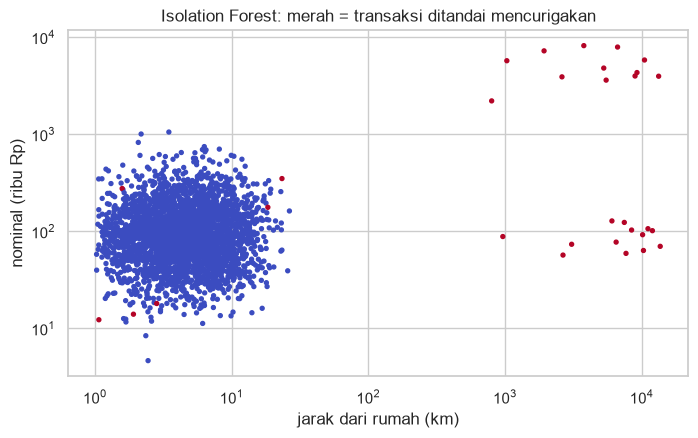

In [11]:
n = 3000
trx = pd.DataFrame({"nominal_ribu": rng.lognormal(4.5, 0.7, n), "jam": rng.normal(14, 3.5, n).clip(0, 23),
                    "jarak_dari_rumah_km": rng.gamma(1.5, 3, n), "luar_negeri": 0})
# separuh anomali bernominal BESAR, separuh bernominal BIASA tetapi terjadi dini hari & jauh / di luar negeri
anom = pd.DataFrame({"nominal_ribu": np.r_[rng.uniform(2000, 9000, 12), rng.lognormal(4.5, 0.4, 13)],
                     "jam": rng.choice([1, 2, 3, 4, 23], 25),
                     "jarak_dari_rumah_km": rng.uniform(500, 15000, 25), "luar_negeri": rng.choice([0, 1], 25, p=[0.3, 0.7])})
trx = pd.concat([trx.assign(anomali_asli=0), anom.assign(anomali_asli=1)], ignore_index=True)

Xa = StandardScaler().fit_transform(np.c_[np.log(trx.nominal_ribu), trx.jam, np.log1p(trx.jarak_dari_rumah_km), trx.luar_negeri])
iso = IsolationForest(contamination=0.01, random_state=0).fit(Xa)
trx["deteksi_iforest"] = (iso.predict(Xa) == -1).astype(int)
z = np.abs((np.log(trx.nominal_ribu) - np.log(trx.nominal_ribu).mean()) / np.log(trx.nominal_ribu).std())
trx["deteksi_zscore"] = (z > 3).astype(int)
for kol in ["deteksi_iforest", "deteksi_zscore"]:
    print(f"{kol:16s}: presisi {precision_score(trx.anomali_asli, trx[kol]):.2f}, recall {recall_score(trx.anomali_asli, trx[kol]):.2f}")

plt.figure(figsize=(8, 4.5))
plt.scatter(trx.jarak_dari_rumah_km + 1, trx.nominal_ribu, c=trx.deteksi_iforest, cmap="coolwarm", s=8)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("jarak dari rumah (km)"); plt.ylabel("nominal (ribu Rp)")
plt.title("Isolation Forest: merah = transaksi ditandai mencurigakan"); plt.show()

Isolation Forest memakai **beberapa fitur sekaligus** sehingga menangkap transaksi aneh yang nominalnya biasa saja
tetapi terjadi dini hari di luar negeri — hal yang terlewat oleh aturan statistik satu variabel (z-score).

## F. Association rule — analisis keranjang belanja minimarket mitra

In [12]:
barang = ["roti", "telur", "susu", "kopi", "gula", "mie instan", "beras", "minyak goreng", "sabun", "teh"]
keranjang = []
for _ in range(2000):
    k = set(rng.choice(barang, rng.integers(1, 5), replace=False))
    if "roti" in k and rng.random() < 0.6: k.add("telur")
    if "kopi" in k and rng.random() < 0.55: k.add("gula")
    if "beras" in k and rng.random() < 0.5: k.add("minyak goreng")
    keranjang.append(k)
N = len(keranjang)
support = {frozenset([b]): sum(b in k for k in keranjang) / N for b in barang}
aturan = []
for a, b in combinations(barang, 2):
    s_ab = sum(a in k and b in k for k in keranjang) / N
    if s_ab < 0.03: continue
    for x, y in [(a, b), (b, a)]:
        conf = s_ab / support[frozenset([x])]
        aturan.append({"aturan": f"{x} → {y}", "support": s_ab, "confidence": conf,
                       "lift": conf / support[frozenset([y])]})
pd.DataFrame(aturan).sort_values("lift", ascending=False).head(8).round(3)

,aturan,support,confidence,lift
48,kopi → gula,0.166,0.652,1.843
49,gula → kopi,0.166,0.468,1.843
0,roti → telur,0.170,0.689,1.842
1,telur → roti,0.170,0.456,1.842
78,beras → minyak goreng,0.156,0.620,1.785
79,minyak goreng → beras,0.156,0.449,1.785
18,telur → susu,0.094,0.253,0.997
19,susu → telur,0.094,0.373,0.997


*Lift* > 1 berarti dua barang dibeli bersama **lebih sering daripada kebetulan**. Rekomendasi: letakkan telur di dekat
roti, gula di dekat kopi, dan buat paket "beras + minyak goreng".

## G. Semi-supervised — memanfaatkan data tak berlabel
Pemateri mencontohkan 1.000 email berlabel dan 30.000 tak berlabel: **memberi label itu mahal**. Di sini bank punya
1.050 data nasabah (2 fitur perilaku yang sudah diskalakan, polanya tidak linear), tetapi **hanya 8 yang sempat
dilabeli** analis. Kita bandingkan:
1. *Supervised* — hanya memakai 8 data berlabel;
2. *Self-training* — model memberi "label semu" pada data yang paling ia yakini, lalu dilatih ulang;
3. *Graph-based* (Label Spreading) — label "menyebar" ke tetangga terdekat mengikuti struktur data.

Berlabel: 8 | tak berlabel: 1042


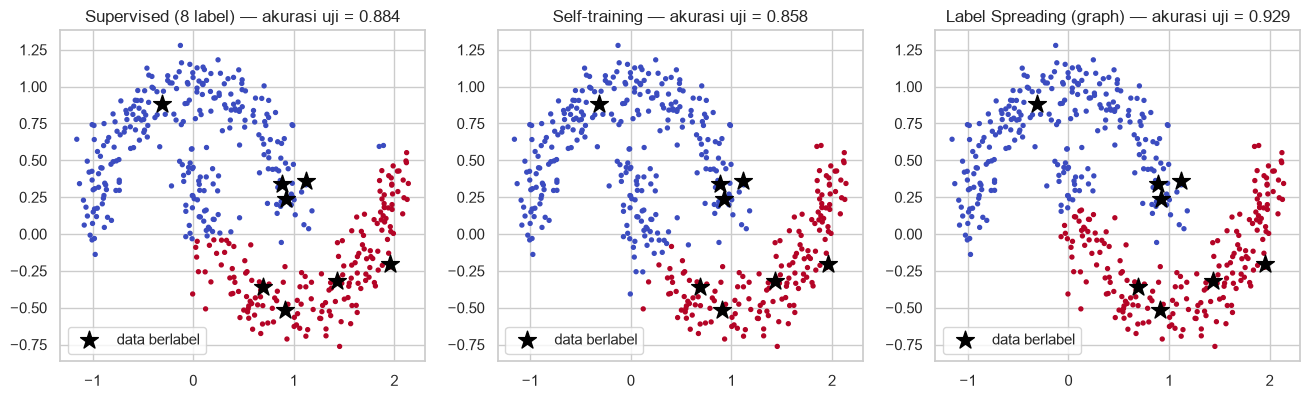

In [13]:
from sklearn.datasets import make_moons
from sklearn.semi_supervised import LabelSpreading
Xs, ys = make_moons(1500, noise=0.12, random_state=0)
Xs_l, Xs_u, ys_l, ys_u = train_test_split(Xs, ys, test_size=0.3, random_state=0)
y_sebagian = np.full(len(ys_l), -1)                       # -1 = tak berlabel
rs = np.random.default_rng(0)
for kelas in (0, 1):
    y_sebagian[rs.choice(np.where(ys_l == kelas)[0], 4, replace=False)] = kelas
ada = y_sebagian != -1
print(f"Berlabel: {ada.sum()} | tak berlabel: {(~ada).sum()}")

m_sup = SVC(gamma=2).fit(Xs_l[ada], y_sebagian[ada])
m_self = SelfTrainingClassifier(KNeighborsClassifier(3), threshold=0.99, max_iter=None).fit(Xs_l, y_sebagian)
m_graf = LabelSpreading(kernel="rbf", gamma=30, alpha=0.1, max_iter=200).fit(Xs_l, y_sebagian)
hasil_semi = {"Supervised (8 label)": m_sup, "Self-training": m_self, "Label Spreading (graph)": m_graf}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, (nama, m) in zip(ax, hasil_semi.items()):
    pred = m.predict(Xs_u)
    a.scatter(Xs_u[:, 0], Xs_u[:, 1], c=pred, cmap="coolwarm", s=8)
    a.scatter(Xs_l[ada, 0], Xs_l[ada, 1], c="black", marker="*", s=180, label="data berlabel")
    a.set_title(f"{nama} — akurasi uji = {accuracy_score(ys_u, pred):.3f}"); a.legend(loc="lower left")
plt.show()

Dengan hanya 8 label, model *supervised* gagal mengikuti bentuk data yang melengkung. *Label Spreading*
memanfaatkan struktur 1.042 data tak berlabel sehingga jauh lebih akurat. *Self-training* tidak selalu membantu:
bila model awal salah yakin, kesalahannya ikut "menular" ke label semu — semi-supervised tetap harus dievaluasi.

## H. Reinforcement learning — robot kurir gudang (Q-learning)

* **Agen**: robot kurir. **Lingkungan**: gudang 6×6 dengan rak (rintangan).
* **Aksi**: atas/bawah/kiri/kanan. **Reward**: +20 sampai tujuan, −10 menabrak rak, −1 per langkah (agar cepat).
* Agen belajar dari *trial and error* untuk memaksimalkan **reward kumulatif** (seperti mobil otonom pada materi).

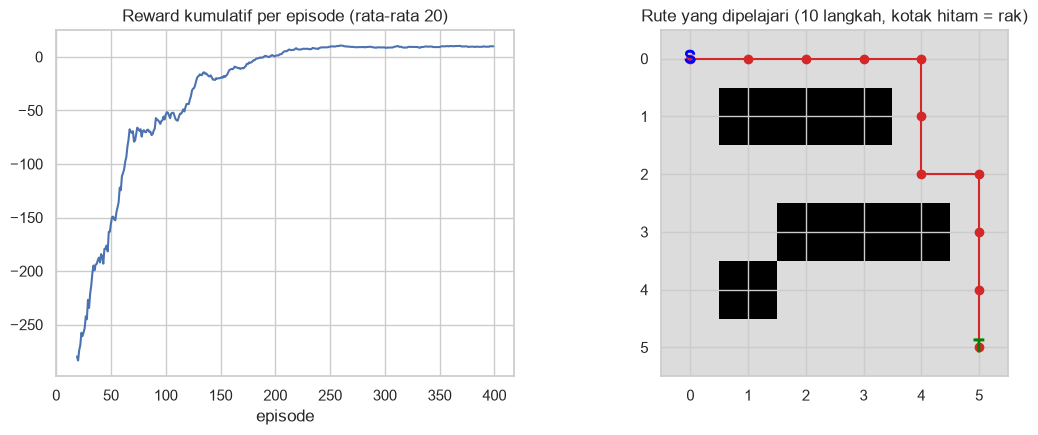

In [14]:
GRID = 6
RAK = {(1, 1), (1, 2), (1, 3), (3, 2), (3, 3), (3, 4), (4, 1)}
MULAI, TUJUAN = (0, 0), (5, 5)
AKSI = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def langkah(s, a):
    r, c = s[0] + AKSI[a][0], s[1] + AKSI[a][1]
    if not (0 <= r < GRID and 0 <= c < GRID): return s, -5, False
    if (r, c) in RAK: return s, -10, False
    if (r, c) == TUJUAN: return (r, c), 20, True
    return (r, c), -1, False

Q = np.zeros((GRID, GRID, 4)); alpha, gamma = 0.5, 0.95
total_reward = []
for ep in range(400):
    s, tot, eps = MULAI, 0, max(0.05, 1 - ep / 250)
    for _ in range(100):
        a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
        s2, r, selesai = langkah(s, a)
        Q[s][a] += alpha * (r + gamma * np.max(Q[s2]) * (not selesai) - Q[s][a])
        s, tot = s2, tot + r
        if selesai: break
    total_reward.append(tot)

s, jalur = MULAI, [MULAI]
while s != TUJUAN and len(jalur) < 30:
    s, _, _ = langkah(s, int(np.argmax(Q[s]))); jalur.append(s)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(pd.Series(total_reward).rolling(20).mean()); ax[0].set_title("Reward kumulatif per episode (rata-rata 20)")
ax[0].set_xlabel("episode")
peta = np.zeros((GRID, GRID))
for r_, c_ in RAK: peta[r_, c_] = -1
ax[1].imshow(peta, cmap="Greys_r", vmin=-1, vmax=0.3)
ax[1].plot([p[1] for p in jalur], [p[0] for p in jalur], "o-", color="tab:red")
ax[1].text(0, 0, "S", ha="center", va="center", color="blue", fontsize=14, weight="bold")
ax[1].text(5, 5, "T", ha="center", va="center", color="green", fontsize=14, weight="bold")
ax[1].set_title(f"Rute yang dipelajari ({len(jalur) - 1} langkah, kotak hitam = rak)"); plt.show()

## I. Kesimpulan

| Bagian | Jenis ML | Hasil utama |
|---|---|---|
| A | Rule-based vs supervised | Model ML mengenali pola penipuan yang tidak tertulis dalam aturan manual. |
| B | Regresi | Linear Regression sudah sangat baik karena hubungan fitur–harga hampir linear — model yang lebih rumit tidak otomatis lebih akurat; kurva derajat polinomial memperlihatkan *underfitting* vs *overfitting*. |
| C | Klasifikasi | Beberapa algoritma dibandingkan dengan validasi silang 5-fold; *decision tree* memperlihatkan aturan yang dipelajari. |
| D | Clustering + PCA | Jumlah cluster dipilih dengan *elbow* & *silhouette*, lalu diberi nama segmen bisnis. |
| E | Deteksi anomali | Isolation Forest (multivariat) menangkap anomali bernominal biasa yang lolos dari z-score satu variabel. |
| F | Association rule | Pasangan roti→telur, kopi→gula, beras→minyak goreng memiliki *lift* > 1. |
| G | Semi-supervised | Dengan 8 label saja, Label Spreading memanfaatkan data tak berlabel dan mengungguli model supervised; self-training perlu hati-hati. |
| H | Reinforcement learning | Agen Q-learning menemukan rute aman tanpa diberi contoh rute. |

Pesan utama pemateri tetap berlaku: **algoritma sudah tersedia dan teruji — tanggung jawab kita adalah menyiapkan data
yang berkualitas, memilih jenis ML yang sesuai dengan masalah (berlabel → klasifikasi/regresi; tidak berlabel →
clustering), mengevaluasi dengan jujur, dan memperhatikan etika.**